# Milestone 3 — Data Splitting, Feature Engineering & Leak-Free Preprocessing Pipeline

**Mục tiêu:** Chứng minh quy trình chuẩn bị dữ liệu tái lập, tách biệt hoàn toàn tập Locked Test, triển khai 4 bậc đặc trưng (`F0 → F1 → F2_safe → F2_plus_emp`) và kiểm chứng bộ tiền xử lý (`Pipeline` + `ColumnTransformer`) chỉ `.fit()` trên dữ liệu huấn luyện. **Không huấn luyện bất kỳ mô hình so sánh cuối nào trong notebook này.**

In [1]:
import json
import os
import sys
import time
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".matplotlib_cache"))

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.data.load_data import load_config
from src.data.splits import load_split_frames
from src.features.engineering import LTFSFeatureEngineer, get_feature_rationale_table
from src.features.preprocessing import OOFSmoothedTargetEncoder, SignedLog1pTransformer, QuantileWinsorizer, build_preprocessing_pipeline

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 140, "savefig.dpi": 300, "axes.titlesize": 11, "axes.titleweight": "bold"})

cfg = load_config()
FIG_DIR = ROOT / cfg["paths"]["figures_dir"]
TABLES_DIR = ROOT / cfg["paths"]["tables_dir"]
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

split_meta = json.loads((ROOT / cfg["paths"]["splits_dir"] / "split_metadata.json").read_text(encoding="utf-8"))
for sname in ("oot_split", "random_split"):
    print(f"=== {sname.upper()} ===")
    display_df = pd.DataFrame(split_meta[sname]["summary"]).T
    print(display_df[["n_rows", "pct_of_total", "n_defaults", "default_rate_pct", "min_date", "max_date"]])
    print("Integrity checks:", split_meta[sname]["integrity_checks"], "\n")

=== OOT_SPLIT ===
             n_rows pct_of_total  ...    min_date    max_date
train        146000      62.6196  ...  2018-08-01  2018-10-22
val           36501      15.6553  ...  2018-08-01  2018-10-22
dev_all      182501      78.2749  ...  2018-08-01  2018-10-22
test_locked   50653      21.7251  ...  2018-10-23  2018-10-31

[4 rows x 6 columns]
Integrity checks: {'uid_overlap_train_val': 0, 'uid_overlap_train_test': 0, 'uid_overlap_val_test': 0, 'feature_row_overlap_dev_test': 0} 

=== RANDOM_SPLIT ===
             n_rows pct_of_total  ...    min_date    max_date
train        149218      63.9998  ...  2018-08-01  2018-10-31
val           37305      16.0002  ...  2018-08-01  2018-10-31
dev_all      186523      79.9999  ...  2018-08-01  2018-10-31
test_locked   46631      20.0001  ...  2018-08-01  2018-10-31

[4 rows x 6 columns]
Integrity checks: {'uid_overlap_train_val': 0, 'uid_overlap_train_test': 0, 'uid_overlap_val_test': 0, 'feature_row_overlap_dev_test': 0} 



## 1. Bảng Cơ Sở Khoa Học Các Đặc Trưng Kỹ Thuật (Feature Engineering Rationale)

In [2]:
rationale_df = get_feature_rationale_table()
print(f"Total documented engineered features: {len(rationale_df)} (3 in F0 + {int((rationale_df['tier'] == 'F1').sum())} in F1)")
print(rationale_df["category"].value_counts())
rationale_df

Total documented engineered features: 32 (3 in F0 + 29 in F1)
category
Domain-driven          11
Aggregation-based       9
Statistical/Ratio       7
Interaction/Anomaly     5
Name: count, dtype: int64


,feature,tier,category,formula,rationale
0,age_at_disbursal,F0,Domain-driven,(DisbursalDate - century_fixed(Date.of.Birth))...,Fixes 8.52% 2-digit year century rollover ('00...
1,avg_acct_age_months,F0,Domain-driven,yrs*12 + mon from AVERAGE.ACCT.AGE,Converts 'Xyrs Ymon' string into numeric month...
2,credit_history_months,F0,Domain-driven,yrs*12 + mon from CREDIT.HISTORY.LENGTH,Converts credit history length string into num...
3,has_bureau_score,F1,Domain-driven,1 if PERFORM_CNS.SCORE >= 300 else 0,Separates the 55.66% unscored/thin-file record...
4,bureau_score_clean,F1,Domain-driven,PERFORM_CNS.SCORE if >= 300 else NaN,Prevents linear/MLP models from treating speci...
5,bureau_unscored_group,F1,Domain-driven,Grouped unscored regime (SCORED/NO_HISTORY/GUA...,Preserves risk heterogeneity observed in M1 ac...
6,bureau_risk_ordinal,F1,Domain-driven,A->1 .. M->13 for scored; 0 for unscored,Ordinal risk tier encoding capturing the broad...
7,estimated_down_payment,F1,Domain-driven,asset_cost - disbursed_amount,Quantifies borrower initial equity buffer / sk...
8,down_payment_ratio,F1,Domain-driven,(asset_cost - disbursed_amount) / asset_cost,Scale-normalized equity share independent of v...
9,ltv_computed,F1,Domain-driven,100.0 * disbursed_amount / asset_cost,Raw ratio of disbursed amount to declared asse...


## 2. Kiểm Chứng Fit-Only-On-Train & Biến Đổi Ma Trận cho Cả 4 Bậc (`F0` -> `F2_plus_emp`)

In [3]:
train_df, val_df, test_df, _, _ = load_split_frames("oot", cfg)
# Keep test_df strictly untouched!
del test_df

y_train = train_df["loan_default"].to_numpy()
y_val = val_df["loan_default"].to_numpy()

results = []
for tier in ("F0", "F1", "F2_safe", "F2_plus_emp"):
    for family in ("linear", "tree"):
        t0 = time.perf_counter()
        pipe = build_preprocessing_pipeline(
            feature_tier=tier,
            model_family=family,
            drop_redundant=(family == "linear"),
            winsor_quantiles=tuple(cfg["preprocessing"]["winsor_quantiles"]),
            te_smoothing=float(cfg["preprocessing"]["target_encoding_smoothing"]),
            te_cv_folds=int(cfg["preprocessing"]["target_encoding_cv_folds"]),
            random_state=int(cfg["project"]["random_seed"]),
        )
        X_tr = pipe.fit_transform(train_df, y_train)
        X_va = pipe.transform(val_df)
        elapsed = round(time.perf_counter() - t0, 2)

        assert X_tr.shape[1] == X_va.shape[1]
        assert np.isfinite(X_tr).all() and np.isfinite(X_va).all()

        results.append(
            {
                "tier": tier,
                "model_family": family,
                "drop_redundant": (family == "linear"),
                "train_shape": f"{X_tr.shape[0]} x {X_tr.shape[1]}",
                "val_shape": f"{X_va.shape[0]} x {X_va.shape[1]}",
                "n_output_features": int(X_tr.shape[1]),
                "non_finite_count": int((~np.isfinite(X_tr)).sum() + (~np.isfinite(X_va)).sum()),
                "fit_transform_sec": elapsed,
            }
        )

prep_summary_df = pd.DataFrame(results)
print(prep_summary_df.to_string(index=False))
(TABLES_DIR / "m3_preprocessing_summary.json").write_text(
    json.dumps({"pipeline_matrix_checks": results, "n_engineered_features": len(rationale_df)}, indent=2, ensure_ascii=False),
    encoding="utf-8",
)

       tier model_family  drop_redundant  train_shape   val_shape  n_output_features  non_finite_count  fit_transform_sec
         F0       linear            True  146000 x 82  36501 x 82                 82                 0               1.55
         F0         tree           False  146000 x 84  36501 x 84                 84                 0               1.36
         F1       linear            True 146000 x 114 36501 x 114                114                 0               2.47
         F1         tree           False 146000 x 117 36501 x 117                117                 0               1.96
    F2_safe       linear            True 146000 x 120 36501 x 120                120                 0               3.40
    F2_safe         tree           False 146000 x 123 36501 x 123                123                 0               3.08
F2_plus_emp       linear            True 146000 x 122 36501 x 122                122                 0               4.12
F2_plus_emp         tree

2156

## 3. Chẩn Đoán Co Giãn Biến Lệch Mạnh và Độ Co Rút Bayesian Của OOF Target Encoding

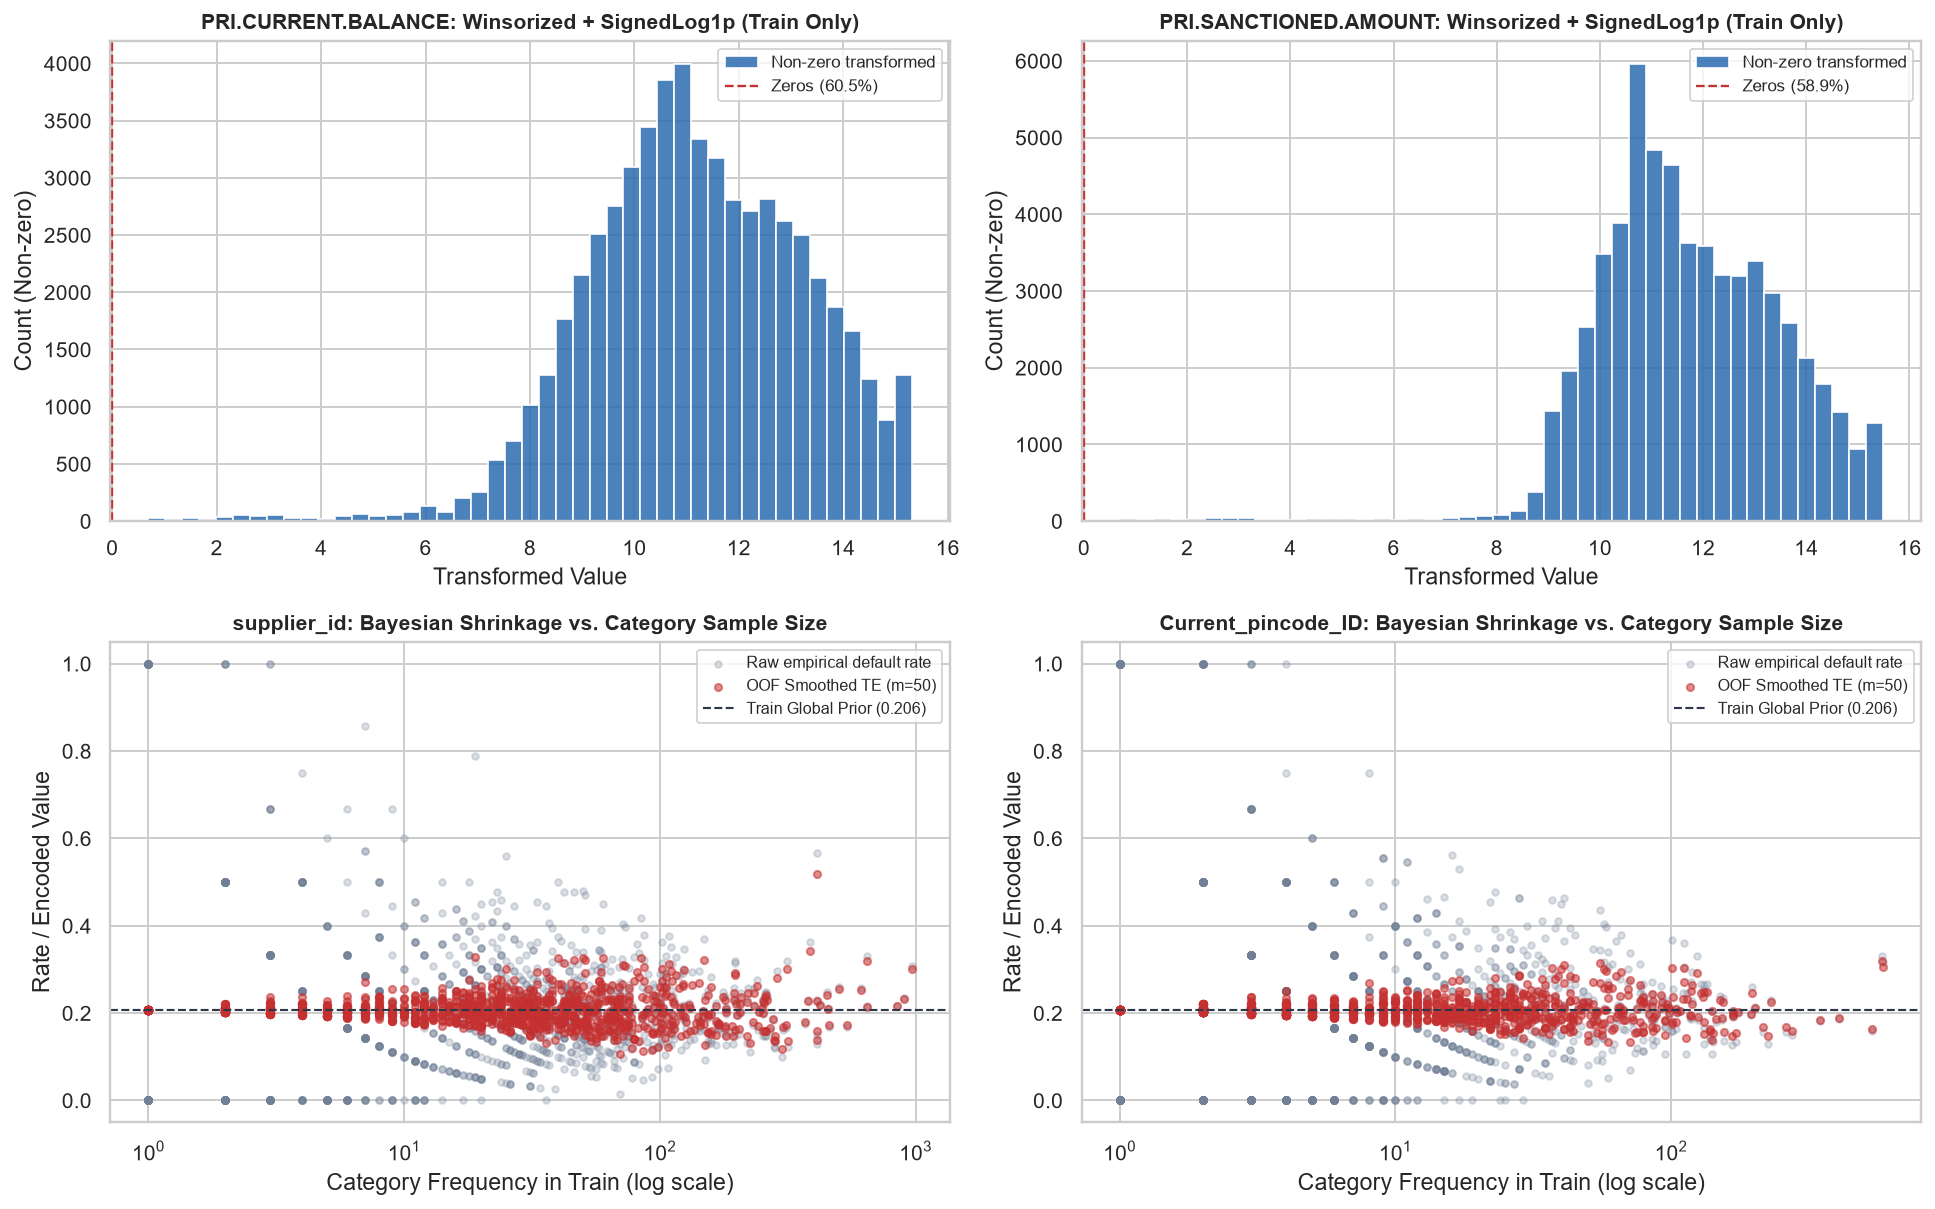

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14.0, 8.8))

# Panel 1 & 2: Raw non-zero log10 vs Winsorized + SignedLog1p on PRI.CURRENT.BALANCE & PRI.SANCTIONED.AMOUNT (train_df only)
for ax, col_name in zip(axes[0], ["PRI.CURRENT.BALANCE", "PRI.SANCTIONED.AMOUNT"]):
    raw_vals = train_df[[col_name]].to_numpy(dtype=np.float64)
    win = QuantileWinsorizer(0.005, 0.995)
    slog = SignedLog1pTransformer()
    trans_vals = slog.fit_transform(win.fit_transform(raw_vals)).ravel()

    ax.hist(trans_vals[trans_vals != 0], bins=45, color="#2b6cb0", alpha=0.85, edgecolor="white", label="Non-zero transformed")
    ax.axvline(0.0, color="#c53030", linestyle="--", linewidth=1.2, label=f"Zeros ({(raw_vals == 0).mean()*100:.1f}%)")
    ax.set_title(f"{col_name}: Winsorized + SignedLog1p (Train Only)")
    ax.set_xlabel("Transformed Value")
    ax.set_ylabel("Count (Non-zero)")
    ax.legend(fontsize=8.5)

# Panel 3 & 4: Shrinkage diagnostics for OOFSmoothedTargetEncoder(m=50) on supplier_id & Current_pincode_ID
prior = float(np.mean(y_train))
enc_diag = OOFSmoothedTargetEncoder(n_splits=5, smoothing=50.0, random_state=42)
oof_vals = enc_diag.fit_transform(train_df[["supplier_id", "Current_pincode_ID"]], y_train)

for idx, (ax, hc_col) in enumerate(zip(axes[1], ["supplier_id", "Current_pincode_ID"])):
    stats_hc = (
        pd.DataFrame({"id": train_df[hc_col].astype(str), "y": y_train, "oof_enc": oof_vals[:, idx]})
        .groupby("id")
        .agg(n=("y", "count"), raw_rate=("y", "mean"), mean_oof_enc=("oof_enc", "mean"))
        .reset_index()
    )
    sample_hc = stats_hc.sample(n=min(1200, len(stats_hc)), random_state=42)
    ax.scatter(sample_hc["n"], sample_hc["raw_rate"], alpha=0.25, s=12, color="#718096", label="Raw empirical default rate")
    ax.scatter(sample_hc["n"], sample_hc["mean_oof_enc"], alpha=0.55, s=14, color="#c53030", label="OOF Smoothed TE (m=50)")
    ax.axhline(prior, color="#2d3748", linestyle="--", linewidth=1.1, label=f"Train Global Prior ({prior:.3f})")
    ax.set_xscale("log")
    ax.set_title(f"{hc_col}: Bayesian Shrinkage vs. Category Sample Size")
    ax.set_xlabel("Category Frequency in Train (log scale)")
    ax.set_ylabel("Rate / Encoded Value")
    ax.legend(fontsize=8, loc="upper right")

fig.tight_layout()
fig.savefig(FIG_DIR / "prep_01_transformation_and_encoding_diagnostics.png", bbox_inches="tight")
plt.show()

**Diễn giải Hình `prep_01_transformation_and_encoding_diagnostics.png`:**
- **Biểu đồ cho thấy gì:** Hàng trên minh họa phép biến đổi `QuantileWinsorizer + SignedLog1p` nén dải giá trị từ hàng chục triệu/1 tỷ INR (và cả phần dư âm `-6.67M`) về phân phối chuẩn tắc gọn gàng. Hàng dưới chứng minh hiệu ứng điều chuẩn của `OOFSmoothedTargetEncoder(m=50)`: những `supplier_id` hay `Current_pincode_ID` ít mẫu ($n_c < 20$, vốn có tỷ lệ vỡ nợ thô dao động cực đoan `0%` hoặc `100%`) đều được rút an toàn về gần `global_prior` (`0.2063`), trong khi ID nhiều mẫu vẫn giữ tín hiệu thực.
- **Tại sao quan trọng:** Xác nhận bằng chứng định lượng rằng hệ thống tiền xử lý kiểm soát đồng thời 3 vấn đề nghiêm trọng phát hiện ở M1: đuôi lệch cực đại, số dư âm và overfitting ở biến định danh nhiều nhãn.
- **Có thể và KHÔNG thể kết luận gì:** Có thể khẳng định pipeline tiền xử lý hoạt động ổn định, không rò rỉ và không tạo `NaN`/`Inf`. **Không thể kết luận** hiệu năng phân loại cuối cùng của mô hình trước khi chạy thí nghiệm kiểm định CV ở Milestone 4.